In [1]:
%load_ext autoreload
%autoreload 2
import numpy as np
import emcee
import corner
from matplotlib import pyplot as plt
from astropy import units as u
from astropy import constants as const
import time
from multiprocessing import Pool

from nfw_profile_heating import NFWProfile
from cluster_error_prop import Cluster_werr
from statistics_functions import log_lik
from load_data_and_var import load_data_and_var, generate_nfws_from_combined_dataset_werr
from plotting import savefig, paper_plot

Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


In [2]:
data, var = load_data_and_var()

In [3]:
all_nfws = generate_nfws_from_combined_dataset_werr(data, var)

In [4]:
nfws = [nfw for nfw in all_nfws if nfw.energies.is_virialized_gaspari]

In [5]:
test_nfw = nfws[0]

In [10]:
rmin = 0.001*test_nfw.R500
rmax = test_nfw.R500
rc=0.1*test_nfw.R500

In [7]:
Tbs = np.logspace(-8, -5)

In [15]:
dHeatdT=[test_nfw.dheating_dT(rmin, rmax, rc, T) for T in Tbs]

In [34]:
dCooldT = [test_nfw.dcooling_dT(rmin, rmax, T).value for T in Tbs]

/Users/eleanorstuart/Desktop/krisp/thermo-idm/cluster_error_prop.py:312: RuntimeWarning: invalid value encountered in sqrt
  return prefactors * np.sqrt(Tk) *ncm**2 *(const.k_B/const.h).value # returns in erg/s /cm3


In [39]:
dDMCooldT= [test_nfw.dDMcooling_dT(rmin, rmax, 1e-27, 1e-2, T500=T).value for T in Tbs]

AttributeError: 'Cluster_werr' object has no attribute 'dDMcooling_dT'

Text(0, 0.5, 'derivative of heating/cooling rate wrt Tb (erg/s/GeV)')

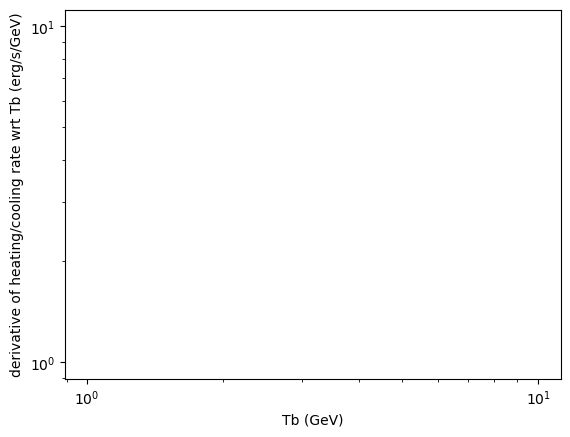

In [38]:
#plt.loglog(Tbs, dHeatdT, label='dHeat/dt')
plt.loglog(Tbs, dCooldT, label='dCool/dt')
plt.loglog(Tbs, dDMCooldT, label='dDMCool/dt')
plt.xlabel('Tb (GeV)')
plt.ylabel('derivative of heating/cooling rate wrt Tb (erg/s/GeV)')


In [33]:
test_nfw.Tbs_norm*u.GeV.to(u.K, equivalencies=u.temperature_energy())

array([0.12450988, 0.12908051, 0.14818355, 0.17003461, 0.1950031 ,
       0.22349954, 0.25597737, 0.29293364, 0.33490822, 0.38248105,
       0.43626646, 0.496904  , 0.56504452, 0.64133064, 0.72637041,
       0.82070324, 0.92475729, 1.03879823, 1.16286992, 1.29672889,
       1.43977574, 1.59098882, 1.74886675, 1.91138854, 2.07600058,
       2.23963961, 2.39879916, 2.5496431 , 2.68816491, 2.81038507,
       2.91257259, 2.99147175, 3.04451222, 3.06998112, 3.06713885,
       3.03626668, 2.97864165, 2.89644239, 2.79259665, 2.67058703,
       2.5342341 , 2.38747731, 2.23417182, 2.07791596, 1.92191908,
       1.76891399, 1.62111326, 1.48020461, 1.34737787, 1.        ])